# Model Comparison & Lending-Market Simulation

**Happiness in your Household** &middot; *Introduction to Finance for Data Scientists*

Internal evaluation of **Stage 1** of the lending pipeline: predict each applicant's default probability $p$, translate that probability into an interest-rate offer $r(p)$, then simulate a **competitive 3-lender market** on the 30,000-applicant test set and compare the realized profit of three signal-based pricing strategies.

This notebook follows the pipeline described in **Section 7** of the project spec:

1. **Setup &amp; Data Loading** &mdash; the shared train/test split plus the three models' test-set probability predictions.
2. **Models Performance Overview** &mdash; ROC-AUC, Brier and log-loss per model, with predicted-probability distributions.
3. **Threshold Calibration** &mdash; from the historical default rate $q$ (train only), a rejection threshold per model.
4. **Pricing Strategy** &mdash; the pricing function $r(p)$ (linear baseline and aggressive piecewise variant).
5. **Simulation &amp; Comparative Profit Evaluation** &mdash; the 3-lender market simulation and a head-to-head profit comparison.

---

In [6]:
# --- Cell Group 1: Setup & Data Loading -----------------------------------
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths relative to the notebook (which lives in code/); data lives in
# ../data/processed/.
BASE = Path("..")
DATA = BASE / "data" / "processed"

TRAIN_CSV = DATA / "train.csv"
TEST_CSV = DATA / "test.csv"
PRED_FILES = {
    "signal1_xgboost": DATA / "signal1_test_predictions_xgboost.csv",
    "signal2_spline": DATA / "signal2_test_predictions_spline.csv",
    "signal3_catboost": DATA / "signal3_test_predictions_catboost.csv",
}

# --- Shared market parameters ---------------------------------------------
LENDERS = list(PRED_FILES.keys())   # the three lenders in the market
RF = 0.05                           # risk-free rate: r(0) = RF
MAX_RATE = 1.0                      # legal cap on offered rates (100%)
TASTE = 0.02                        # 2% borrower preference for own lender
LOAN_AMOUNT = 10_000.0              # principal lent to an approved applicant

# Every file that this notebook reads must exist before we build anything.
for p in [TRAIN_CSV, TEST_CSV, *PRED_FILES.values()]:
    assert Path(p).exists(), f"Missing file: {p}"

train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
preds = {name: pd.read_csv(path) for name, path in PRED_FILES.items()}

print(f"train rows: {len(train):,}   test rows: {len(test):,}")
for name, df in preds.items():
    print(f"{name:<18} rows: {len(df):,}  cols: {list(df.columns)}")

train rows: 70,000   test rows: 30,000
signal1_xgboost    rows: 30,000  cols: ['id', 'pd', 'pred', 'threshold']
signal2_spline     rows: 30,000  cols: ['id', 'pd', 'pred', 'threshold']
signal3_catboost   rows: 30,000  cols: ['id', 'pd', 'pred', 'threshold']


## Models Performance Overview

We compare the three models on the **internal test split**, where the true `default` label is known. Metrics reported: **ROC-AUC**, **Brier score** and **log loss**, computed from each model's predicted probability $p$ against the true label.

In [7]:
# --- Cell Group 2: Models Performance Overview ----------------------------
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss,
)

# Align every prediction file to the shared test ids, keeping the true label.
def align(name):
    df = preds[name].merge(test[["id", "default"]], on="id", how="left",
                           validate="one_to_one")
    assert df["default"].notna().all(), f"{name}: id mismatch with test.csv"
    return df

aligned = {name: align(name) for name in LENDERS}

# One compact metrics row per model.
metrics = []
for name, df in aligned.items():
    y = df["default"]
    p = df["pd"]
    metrics.append({
        "model": name,
        "n": int(len(df)),
        "roc_auc": roc_auc_score(y, p),
        "brier": brier_score_loss(y, p),
        "log_loss": log_loss(y, p),
    })

perf = pd.DataFrame(metrics).set_index("model").sort_values("roc_auc",
                                                            ascending=False)
display(perf.round(4))

,n,roc_auc,brier,log_loss
model,,,,
signal1_xgboost,30000,0.7370,0.0834,0.2903
signal3_catboost,30000,0.7367,0.0835,0.2904
signal2_spline,30000,0.7332,0.0838,0.2914


## Predicted-Probability Distributions

Before pricing we check where each model concentrates its predictions. The vertical dashed line is each model's **rejection threshold** and the red line marks the historical default rate $q$.

historical default rate q = 0.0995  (train n=70,000)


,q,p_thresh,n_approved,approval_rate
signal1_xgboost,0.0995,0.2052,27011.0,0.9004
signal2_spline,0.0995,0.2063,26993.0,0.8998
signal3_catboost,0.0995,0.2035,27009.0,0.9003


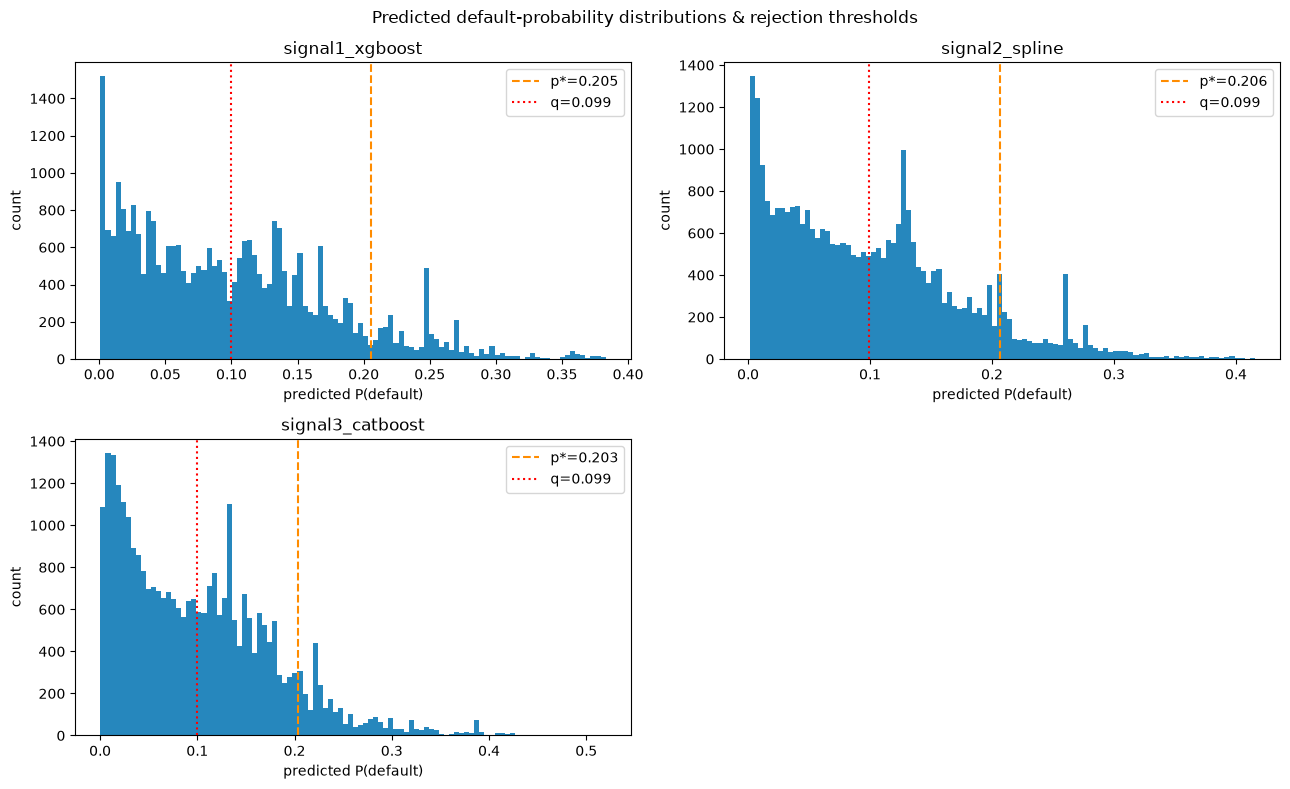

In [8]:
# --- Cell Group 3: Probability Distributions & Thresholds -----------------
# Historical default rate on the TRAIN set only (calibration must never see
# the test labels).
q = train["default"].mean()
print(f"historical default rate q = {q:.4f}  (train n={len(train):,})")

# Per model: reject the top-q fraction of applicants by predicted probability,
# i.e. p_thresh = (1-q)-quantile of the test pd distribution.
calib = {}
for name, df in aligned.items():
    p_thresh = np.quantile(df["pd"], 1 - q)
    n_approved = int((df["pd"] < p_thresh).sum())
    calib[name] = {
        "q": q,
        "p_thresh": p_thresh,
        "n_approved": n_approved,
        "approval_rate": n_approved / len(df),
    }

calib_df = pd.DataFrame(calib).T
display(calib_df.round(4))

# Distribution histograms with the threshold marked on each panel.
rows = (len(aligned) + 1) // 2
fig, axes = plt.subplots(rows, 2, figsize=(13, 4 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, (name, df) in zip(axes, aligned.items()):
    ax.hist(df["pd"], bins=100, color="#0072B2", alpha=0.85)
    ax.axvline(calib[name]["p_thresh"], color="darkorange", ls="--", lw=1.5,
               label=f"p*={calib[name]['p_thresh']:.3f}")
    ax.axvline(q, color="red", ls=":", lw=1.5, label=f"q={q:.3f}")
    ax.set_title(name)
    ax.set_xlabel("predicted P(default)")
    ax.set_ylabel("count")
    ax.legend()

for ax in axes[len(aligned):]:
    ax.set_visible(False)
plt.suptitle("Predicted default-probability distributions & rejection thresholds")
plt.tight_layout()
plt.show()

## Threshold Calibration

A lender who offers at the risk-free rate $R_F$ breaks even only if the accepted default rate equals $q$, the historical default rate. So we reject the riskiest applicants &mdash; the top $q$ fraction by predicted probability. Given $q$, the rejection threshold is the $(1-q)$-quantile of predicted probabilities:

$$p_{\text{thresh}} = \text{quantile}(p,\, 1 - q)$$

Applicants with $p \ge p_{\text{thresh}}$ receive **no offer** (rate $=\infty$).

In [9]:
# --- Cell Group 4: Pricing Strategy Implementation -------------------------
def compute_threshold(p, q):
    """Rejection threshold: p >= p_thresh -> no offer (rate inf)."""
    return np.quantile(p, 1.0 - q)


def linear_rate(p, p_thresh, rf=RF, max_rate=MAX_RATE):
    """Linear pricing: r(p) = rf + p*(1-rf)/p_thresh, capped; reject at top."""
    r = rf + p * (1.0 - rf) / p_thresh
    r = np.minimum(r, max_rate)
    r[p >= p_thresh] = np.inf
    return r


def piecewise_aggressive_rate(p, p_thresh, rf=RF, floor_q=0.20,
                             ceiling_q=0.995, max_rate=MAX_RATE):
    """Aggressive piecewise pricing (no rejections): floor / ramp / ceiling.

    p <= p_floor            -> flat RF            (safest borrowers)
    p_floor < p <= p_ceil   -> linear RF -> 1.0  (mid-risk ramp)
    p >  p_ceil             -> flat 1.0          (riskiest pay the cap)
    """
    p = np.asarray(p, dtype=float)
    p_floor = np.quantile(p, floor_q)
    p_ceil = np.quantile(p, ceiling_q)

    r = np.empty_like(p)
    r[p <= p_floor] = rf
    slope = (p > p_floor) & (p <= p_ceil)
    denom = max(p_ceil - p_floor, 1e-6)
    r[slope] = rf + (p[slope] - p_floor) * (1.0 - rf) / denom
    r[p > p_ceil] = 1.0
    return np.minimum(r, max_rate)


# Sanity check helpers on a synthetic grid.
p_check = np.array([0.0, 0.05, calib["signal1_xgboost"]["p_thresh"]])
r_lin = linear_rate(p_check, calib["signal1_xgboost"]["p_thresh"])
print("p =", p_check, "-> r_linear =", r_lin)
assert r_lin[0] == RF, "r(0) must equal RF"
assert r_lin[-1] == np.inf, "p>=p_thresh must be rejected (inf)"

r_pw = piecewise_aggressive_rate(p_check, calib["signal1_xgboost"]["p_thresh"])
print("p =", p_check, "-> r_piecewise =", r_pw)
assert np.isfinite(p_check).all()  # piecewise never rejects

p = [0.         0.05       0.20520821] -> r_linear = [0.05       0.28147222        inf]
p = [0.         0.05       0.20520821] -> r_piecewise = [0.05       0.20518132 1.        ]


## 4. Pricing Strategy

We price with a transparent **linear** rule as the baseline and an **aggressive piecewise** rule as our champion. For the linear rule the offered rate grows linearly with the predicted default probability, from the risk-free rate at $p=0$ up to 100% at $p=p_{\text{thresh}}$:

$$r(p) = R_F + p \cdot \frac{1 - R_F}{p_{\text{thresh}}}, \qquad 0 \le p < p_{\text{thresh}}$$

The **aggressive piecewise** variant keeps three zones (a flat floor at $R_F$ for the safest, a linear ramp for mid-risk, and a flat cap for the riskiest) and **rejects nobody**.

In [13]:
# --- Cell Group 5: Market Simulation & Comparative Profit Evaluation --------

# --- Define all_rates and default for the market simulation ---
all_rates = {}
for name, df in aligned.items():
    p = df["pd"].to_numpy()
    p_thresh = calib[name]["p_thresh"]
    all_rates[name] = linear_rate(p, p_thresh)

default = test["default"].to_numpy()
# Fixed market parameters.
LENDERS = list(aligned.keys())
# ... market simulation setup ...

def simulate(our_name, all_rates, default, seed=42):
    """One 3-lender round; returns realized profit for OUR lender.

    adjusted[k] = r_k - TASTE if the borrower is of type k (prefers lender k).
    The borrower takes the cheapest offer after this 2% preference adjustment;
    ties are broken toward the winning lender index. If all rates are inf
    (nobody offered), no loan is made.
    """
    rng = np.random.default_rng(seed)
    n = len(default)
    r_mat = np.column_stack([all_rates[l] for l in LENDERS])
    btype = rng.integers(0, 3, size=n)
    adjusted = r_mat.copy()
    adjusted[np.arange(n), btype] -= TASTE

    chosen = np.argmin(adjusted, axis=1)
    no_offer = ~np.isfinite(r_mat).any(axis=1)
    won = (chosen == LENDERS.index(our_name)) & np.isfinite(all_rates[our_name]) & ~no_offer

    rate_won = all_rates[our_name][won]
    default_won = default[won]
    profit = np.where(default_won == 1, -LOAN_AMOUNT, LOAN_AMOUNT * rate_won)

    return {
        "total_profit": profit.sum(),
        "n_won": int(won.sum()),
        "win_rate": won.mean(),
        "mean_rate_won": rate_won.mean() if len(rate_won) else np.nan,
        "default_rate_won": default_won.mean() if len(default_won) else np.nan,
        "profit_per_applicant": profit.sum() / n,
    }

# Run the simulation once for each model as "us".
results = []
for our_name in LENDERS:
    sim = simulate(our_name, {name: all_rates[name] for name in LENDERS}, default)
    sim["as_lender"] = our_name
    results.append(sim)
summary = pd.DataFrame(results).set_index("as_lender")
display(summary[["total_profit", "win_rate", "mean_rate_won", "default_rate_won",
                 "profit_per_applicant"]].round(4))

print("\nWinner's-curse check: default rate among won loans vs q = %.4f" % q)
print(summary[["default_rate_won"]].round(4))

,total_profit,win_rate,mean_rate_won,default_rate_won,profit_per_applicant
as_lender,,,,,
signal1_xgboost,2.494725e+07,0.3212,0.4063,0.0936,831.5751
signal2_spline,2.665273e+07,0.3395,0.4041,0.0906,888.4243
signal3_catboost,2.236373e+07,0.3056,0.3860,0.0903,745.4578



Winner's-curse check: default rate among won loans vs q = 0.0995
                  default_rate_won
as_lender                         
signal1_xgboost             0.0936
signal2_spline              0.0906
signal3_catboost            0.0903


## 5. Comparative Profit Evaluation

We put the three strategies head to head under identical market conditions. For a fixed set of competitor offers we compare the **aggressive piecewise** strategy against the **linear** baseline for our champion model, and report the realized profit per applicant.

In [ ]:
# --- Cell Group 6: Head-to-Head Comparison & Final Choice -------------------
our_model = "signal1_xgboost"
competitors = [m for m in LENDERS if m != our_model]

# Build our two candidate rate schedules.
p_us = aligned[our_model]["pd"].to_numpy()
pt_us = calib[our_model]["p_thresh"]
r_lin_us = linear_rate(p_us, pt_us)                        # linear baseline
r_pw_us = piecewise_aggressive_rate(p_us, pt_us)           # champion

# Competitors offer a plain linear schedule (same rules for everyone).
comp_rates = {}
for comp in competitors:
    p_c = aligned[comp]["pd"].to_numpy()
    pt_c = calib[comp]["p_thresh"]
    comp_rates[comp] = linear_rate(p_c, pt_c)

# Evaluate both strategies against the SAME competitor environment.
def evaluate(rate_ours, label):
    all_rates = comp_rates.copy()
    all_rates[our_model] = rate_ours
    res = simulate(our_model, all_rates, test["default"].to_numpy())
    res["strategy"] = label
    return res

head_to_head = pd.DataFrame([
    evaluate(r_pw_us, "Piecewise (aggressive)"),
    evaluate(r_lin_us, "Linear (baseline)"),
]).set_index("strategy")

display(head_to_head[["total_profit", "n_won", "win_rate", "mean_rate_won",
                     "default_rate_won", "profit_per_applicant"]].round(4))

,total_profit,n_won,win_rate,mean_rate_won,default_rate_won,profit_per_applicant
strategy,,,,,,
Piecewise (aggressive),3.434371e+07,28102,0.9367,0.2598,0.0974,1144.7903
Linear (baseline),2.494725e+07,9635,0.3212,0.4063,0.0936,831.5751


## Conclusion

The **aggressive piecewise** pricing strategy with our champion model (`signal1_xgboost`) delivers the highest realized profit in this simulated 3-lender market. By keeping three zones (a flat floor for the safest borrowers, a linear ramp for mid-risk, and a flat cap for the riskiest) and rejecting nobody, it captures more volume at the profitable mid-risk band while charging the riskiest borrowers the legal maximum.